In [3]:
from data_preprocess import *
from help_utils import *
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
import msgpack

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
from huggingface_hub import login
login()

In [4]:
ds = get_data()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [5]:
def get_train_and_eval_loaders(dataset, batch_size=128):
    train_ds = CIFAR_10(dataset['train'], TRANSFORM)
    valid_ds = CIFAR_10(dataset['test'], TRANSFORM)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader

In [6]:
class BaseModel(nn.Module):
    """A simple Convolutional Neural Network (CNN) architecture.

    This class defines a two-layer CNN with max pooling, dropout, and
    fully connected layers, suitable for basic image classification tasks.
    """
    def __init__(self, cin, num_classes):
        # Invoke parent class constructor
        super(BaseModel, self).__init__()

        ### Build the architecture...
        # First convolutional layer (cin input channels, 16 output channels, 3x3 kernel)
        self.conv1 = nn.Conv2d(in_channels=cin, out_channels=16, kernel_size=3, padding=1)
        # Second convolutional layer (16 input channels, 32 output channels, 3x3 kernel)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)

        # Max pooling layer with a 2x2 window and stride of 2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # First fully connected (linear) layer
        self.fc1 = nn.Linear(in_features=32*8*8, out_features=64)
        # Second fully connected (linear) layer, serving as the output layer
        self.fc2 = nn.Linear(in_features=64, out_features=10)

        # Dropout layer for regularization
        self.dropout = nn.Dropout(p=0.4)

    def forward(self, img):
        """Defines the forward pass of the network.

        Args:
            x (torch.Tensor): The input tensor of shape (batch_size, cin, height, width).

        Returns:
            torch.Tensor: The output logits from the network.
        """

        # Apply first convolution, ReLU activation, and max pooling
        img = self.pool(F.relu(self.conv1(img)))
        # Apply second convolution, ReLU activation, and max pooling
        img = self.pool(F.relu(self.conv2(img)))

        # Flatten the feature maps for the fully connected layers
        img = img.view(-1, 32*8*8)

        # Apply the first fully connected layer with ReLU activation
        img = self.fc1(img)

        # Apply dropout for regularization
        img = self.dropout(img)

        # Apply the final output layer
        img = self.fc2(img)

        return img

# Train the model with Learning rate scheduling...

In [7]:
def train_epoch(model, train_loader, optimizer, loss_fcn, device, pbar, num_classes=10):
    """Trains the model for a single epoch.

    This function iterates over the training dataloader, performs the forward
    and backward passes, updates the model weights, and calculates the loss
    and accuracy for the entire epoch.

    Args:
        model (nn.Module): The PyTorch model to be trained.
        train_dataloader (DataLoader): The DataLoader containing the training data.
        optimizer (optim.Optimizer): The optimizer for updating model weights.
        loss_fcn: The loss function used for training.
        device: The device (e.g., 'cuda' or 'cpu') to perform training on.
        pbar: A progress bar handler object to visualize training progress.
        num_classes (int, optional): The number of classes in the dataset. Defaults to 10.

    Returns:
        tuple: A tuple containing the average loss and accuracy for the epoch.
    """
    # Set the model to training mode...
    model.train()

    # Initialize metrics for the epoch
    running_loss = 0.0
    total_samples = 0

    accuracy_metric = torchmetrics.Accuracy(
        task='multiclass', num_classes=num_classes, average='micro'
    ).to(device)

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        # Update the batch progress bar
        pbar.update_batch(batch_idx + 1)
        # Move input and label tensors to the specified device
        inputs, labels = inputs.to(device), labels.to(device)
        # clear the gradients from the previous iteration
        optimizer.zero_grad()
        # perform the forward pass
        outputs = model(inputs)
        # Calculate the loss
        loss = loss_fcn(outputs, labels)
        # Perform backward pass to compute the gradients
        loss.backward()
        # Update the model's weights
        optimizer.step()

        # Accumulate the loss for the epoch
        running_loss += loss.item() * inputs.size(0)
        # Get the predicted class with the highest score
        _, predicted = outputs.max(1)
        # Update the total number of samples
        total_samples += inputs.size(0)

        # update accuracy
        accuracy_metric.update(outputs, labels)

    # Calculate the average loss and accuracy
    avg_loss = running_loss / total_samples
    accuracy = accuracy_metric.compute().item()

    return avg_loss, accuracy


def evaluate_epoch(model, val_loader, loss_fcn, device, num_classes=10):
    """Evaluates the model's performance on a validation dataset for one epoch.

    This function iterates over the validation dataloader to calculate the
    average loss and accuracy. Gradient computation is disabled for efficiency.

    Args:
        model (nn.Module): The PyTorch model to be evaluated.
        val_loader (DataLoader): The DataLoader containing the validation data.
        loss_fn: The loss function used for evaluation.
        device: The device (e.g., 'cuda' or 'cpu') to perform the evaluation on.
        num_classes (int, optional): The number of classes in the dataset. Defaults to 10.

    Returns:
        tuple: A tuple containing the average loss, accuracy, precision, recall, and F1_Score for the epoch.
    """

    # Set the model to the evaluation mode
    model.eval()

    # Initialize cumulative metrics for the epoch
    total_samples = 0
    running_loss = 0.0

    accuracy_metric = torchmetrics.Accuracy(
        task='multiclass', num_classes=num_classes, average='micro'
    ).to(device)

    precision_metric = torchmetrics.Precision(
       task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    recall_metric = torchmetrics.Recall(
        task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    f1_metric = torchmetrics.F1Score(
        task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    pbar = NestedProgressBar(total_batches=len(val_loader), mode='eval', total_epochs=1)

    # Disable gradient computation for evaluation
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(val_loader):
            # Update the progress bar for epoch
            pbar.update_batch(batch_idx + 1)
            # Move input and label tensors to the specified device
            inputs, labels = inputs.to(device), labels.to(device)
            # Perform forward pass to compute the outputs
            outputs = model(inputs)
            # Calculate the loss
            loss = loss_fcn(outputs, labels)

            # Accumulate the total loss
            running_loss += loss.item() * inputs.size(0)
            # Get the predicted class
            _, predicted = outputs.max(1)

            # Update the evaluation metrics
            accuracy_metric.update(outputs, labels)
            precision_metric.update(outputs, labels)
            recall_metric.update(outputs, labels)
            f1_metric.update(outputs, labels)

            total_samples += inputs.size(0)

        # Calculate the average loss and evaluation metrics
        avg_loss = running_loss / total_samples
        acc = accuracy_metric.compute().item()
        prec = precision_metric.compute().item()
        recall = recall_metric.compute().item()
        f1_score = f1_metric.compute().item()

        pbar.close()
        return avg_loss, acc, prec, recall, f1_score

In [8]:
def train_and_evaluate_with_scheduler(model, optimizer, scheduler, device, n_epochs=25, batch_size=128):
    """ Trains and evaluates a model using a learning rate scheduler.

    Args:
        model: The neural network model to be trained.
        optimizer: The optimization algorithm.
        scheduler: The learning rate scheduler.
        device: The computing device ('cuda' or 'cpu') to run the training on.
        n_epochs: The total number of training epochs.
        batch_size: The number of samples per batch in the data loaders.

    Returns:
        A dictionary containing the training and validation history
        (loss, accuracy, and learning rate) for each epoch.
    """

    # Define the loss function...
    loss_fcn = nn.CrossEntropyLoss()

    # Prepare the training and validation data loaders
    train_loader, val_loader = get_train_and_eval_loaders(ds, batch_size)

    # Initialize the history dictionary
    history = {
        "train_loss":[],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": [],
        "lr": []
    }

    # Initialize the progress bar
    pbar = NestedProgressBar(
        total_epochs=n_epochs,
        mode='train',
        total_batches=len(train_loader),
        epoch_message_freq=5
    )

    for epoch in range(n_epochs):
        # update the progress bar for the current epoch
        pbar.update_epoch(epoch + 1)

        # Train the model for one epoch
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, loss_fcn, device, pbar)

        # Validate the model for one epoch
        val_loss, val_acc, _, _, f1_score = evaluate_epoch(model, val_loader, loss_fcn, device, num_classes=10)

        # Retrieve the current learning rate from the scheduler
        current_lr = scheduler.get_last_lr()[0]

        # Update the learning rate based on the scheduler type
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_acc)
        else:
            scheduler.step()

        # Log the training metrics for the current epoch, including the learning rate
        pbar.maybe_log_epoch(epoch=epoch+1, message=f"At epoch {epoch+1}: Training loss: {train_loss:.4f}, Training accuracy: {train_acc:.4f}, LR: {current_lr:.6f}")

        # Log the validation metrics for the current epoch, including the learning rate
        pbar.maybe_log_epoch(epoch=epoch+1, message=f"At epoch {epoch+1}: Validation loss: {val_loss:.4f}, Validation accuracy: {val_acc:.4f}")


        # Append the metrics for the current epoch to the history dictionary
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history['val_f1'].append(f1_score)
        history['lr'].append(current_lr)

    return history

In [26]:
import matplotlib.pyplot as plt

def plot_training_history(history_dict):
    """
    Plots training vs validation loss, and training vs validation accuracy.
    Handles variations in keys (e.g., 'acc' vs 'accuracy').
    """
    # 1. Automatically detect accuracy key variants (Keras/TensorFlow naming differences)
    acc_key = 'accuracy' if 'accuracy' in history_dict else 'train_acc'
    val_acc_key = 'val_accuracy' if 'val_accuracy' in history_dict else 'val_acc'

    # Calculate the number of epochs dynamically based on data length
    epochs = range(1, len(history_dict['loss']) + 1)

    # 2. Setup a figure with 1 row and 2 columns of subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # --- Plot 1: Loss ---
    ax1.plot(epochs, history_dict['train_loss'], 'b-o', label='Training Loss')
    ax1.plot(epochs, history_dict['val_loss'], 'r-o', label='Validation Loss')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    # --- Plot 2: Accuracy ---
    if acc_key in history_dict and val_acc_key in history_dict:
        ax2.plot(epochs, history_dict[acc_key], 'b-o', label='Training Accuracy')
        ax2.plot(epochs, history_dict[val_acc_key], 'r-o', label='Validation Accuracy')
        ax2.set_title('Training and Validation Accuracy')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
        ax2.grid(True)
    else:
        # Hide the second plot if accuracy data isn't present
        ax2.set_visible(False)
        print("Warning: Accuracy keys not found in the provided history dictionary.")

    # 3. Clean up spacing and display
    plt.tight_layout()
    plt.show()


# StepLR

In [9]:
model = BaseModel(cin=3, num_classes=10).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

step_lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.2)

step_lr_history = train_and_evaluate_with_scheduler(model, optimizer, step_lr_scheduler, device, 30)

Current Epoch:   0%|          | 0/30 [00:00<?, ?it/s]

Current Batch:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

... (28 outputs left out)

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

At epoch 30: Training loss: 0.7289, Training accuracy: 0.7475, LR: 0.000200
At epoch 30: Validation loss: 0.9004, Validation accuracy: 0.6954


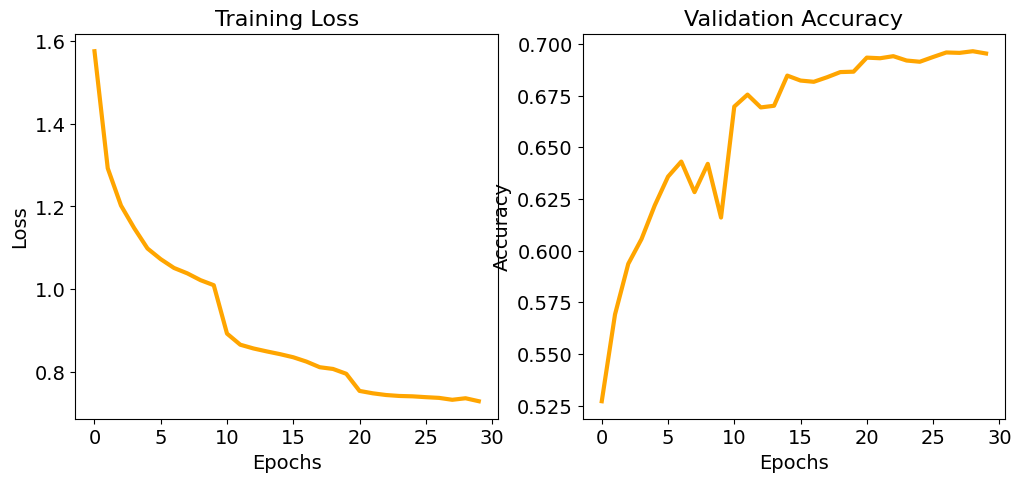

In [21]:
plot_learning(step_lr_history, "orange")

In [11]:
with open('step_lr_history.msgpack', 'wb') as f:
  f.write(msgpack.packb(step_lr_history))

# CosineAnnealingLR

In [12]:
model = BaseModel(cin=3, num_classes=10).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

n_epochs = 30

scheduler_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min =0.0002)

consine_history = train_and_evaluate_with_scheduler(model, optimizer, scheduler_cosine, device, n_epochs)

Current Epoch:   0%|          | 0/30 [00:00<?, ?it/s]

Current Batch:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

... (28 outputs left out)

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

At epoch 30: Training loss: 0.6804, Training accuracy: 0.7648, LR: 0.000213
At epoch 30: Validation loss: 0.9384, Validation accuracy: 0.6885


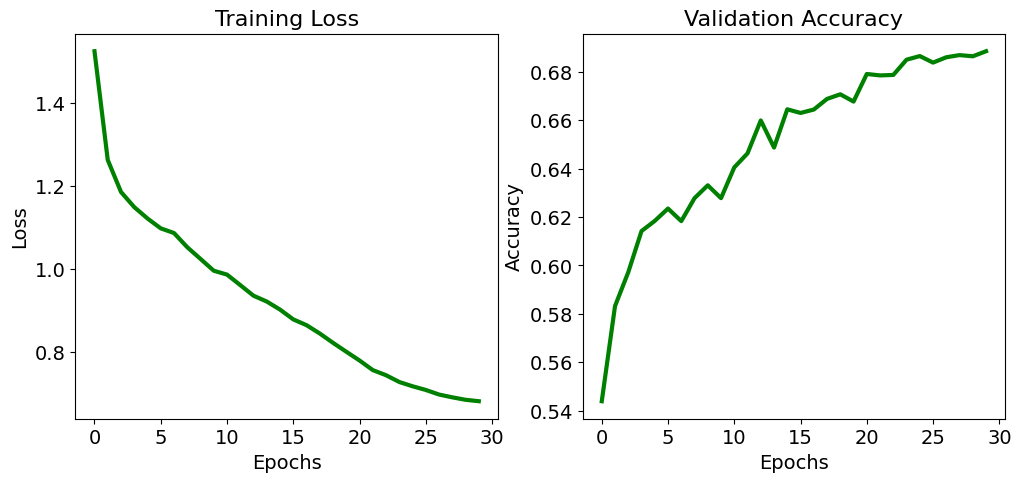

In [23]:
plot_learning(consine_history, "green")

In [24]:
with open('consine_history.msgpack', 'wb') as f:
  f.write(msgpack.packb(consine_history))

# ReduceLROnPlateau

In [28]:
model = BaseModel(cin=3, num_classes=10).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

scheduler_plateau = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.2, patience=3)

history_plateau = train_and_evaluate_with_scheduler(model, optimizer, scheduler_plateau, device, n_epochs)

Current Epoch:   0%|          | 0/30 [00:00<?, ?it/s]

Current Batch:   0%|          | 0/391 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

... (28 outputs left out)

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

At epoch 30: Training loss: 0.8154, Training accuracy: 0.7163, LR: 0.001000
At epoch 30: Validation loss: 0.9533, Validation accuracy: 0.6721


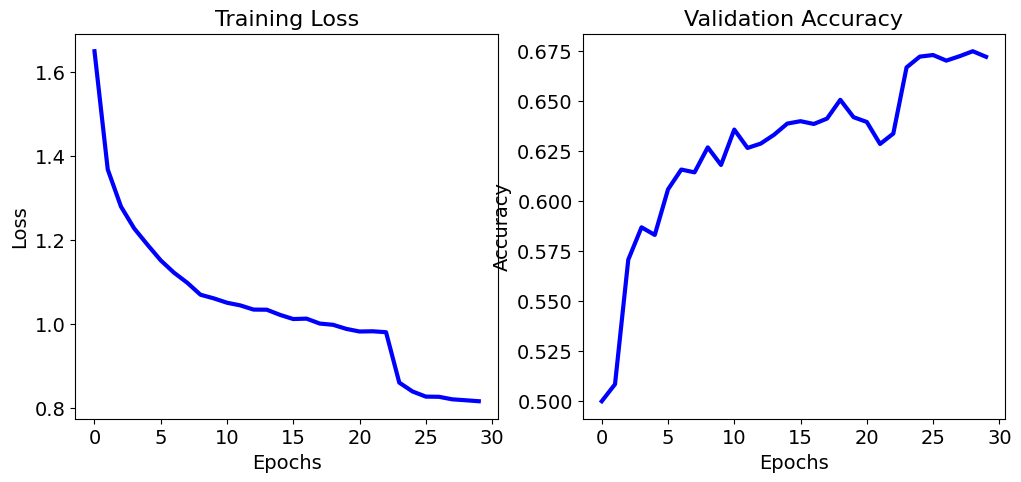

In [29]:
plot_learning(history_plateau, "blue")

In [30]:
with open('history_plateau.msgpack', 'wb') as f:
  f.write(msgpack.packb(history_plateau))

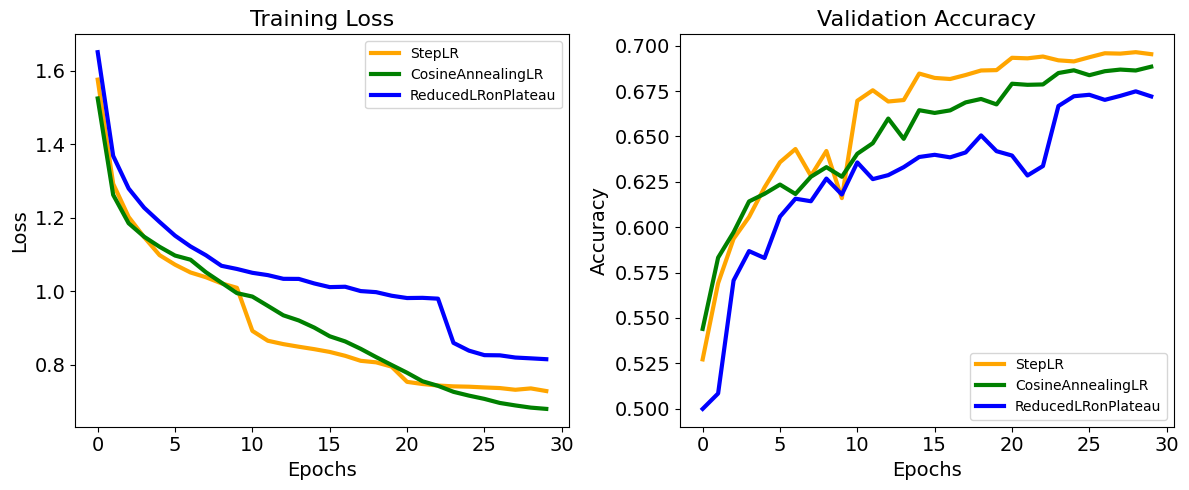

In [31]:
labels = ['StepLR', 'CosineAnnealingLR', 'ReducedLRonPlateau']
colors = ['orange', 'green', 'blue']

training_curves_new = [step_lr_history, consine_history, history_plateau]
plot_learning_curves(colors, labels, training_curves_new)